# K-Nearest Neighbors (KNN) Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

K-Nearest Neighbors (KNN) is a non-parametric supervised learning algorithm that classifies observations based on the classes of their nearest neighbors in the feature space.

This notebook develops a KNN classifier using the PCA-transformed dataset to predict loan default.

The objectives are to:

- Train a KNN classifier.
- Predict applicant default status.
- Evaluate classification performance.
- Investigate the effect of the number of neighbors (K).
- Compare the results with previous machine learning models.

# Import Required Libraries

The following libraries are used for training, evaluating, and visualizing the KNN classifier.

In [2]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed datasets prepared in Notebook 05 are loaded for training and evaluating the KNN classifier.

In [3]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train KNN Classifier

A K-Nearest Neighbors classifier is trained using the training dataset.

For this study, **K = 5** is selected as the initial value, representing a balance between model complexity and generalization.

In [4]:
# ============================================================
# Train KNN
# ============================================================

knn_model = KNeighborsClassifier(
    n_neighbors=5,
    metric="minkowski",
    p=2
)

knn_model.fit(
    X_train,
    y_train
)

print("KNN model trained successfully.")

KNN model trained successfully.


# Generate Predictions

The trained classifier predicts both class labels and the probability of default for the testing dataset.

In [5]:
# ============================================================
# Predictions
# ============================================================

y_pred = knn_model.predict(X_test)

y_prob = knn_model.predict_proba(X_test)[:,1]

# Model Evaluation

The KNN classifier is evaluated using standard classification metrics.

In [6]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.914329
1,Precision,0.244966
2,Recall,0.029406
3,F1 Score,0.052509
4,ROC AUC,0.591036


# Confusion Matrix

The confusion matrix summarizes the classification performance of the KNN model.

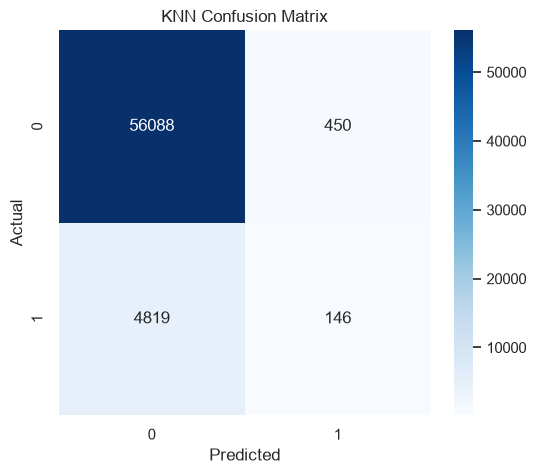

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("KNN Confusion Matrix")

plt.show()

# Classification Report

The classification report provides precision, recall, F1-score, and support for each class.

In [8]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.92      0.99      0.96     56538
           1       0.24      0.03      0.05      4965

    accuracy                           0.91     61503
   macro avg       0.58      0.51      0.50     61503
weighted avg       0.87      0.91      0.88     61503



# ROC Curve

The ROC Curve evaluates the classifier's ability to distinguish between default and non-default applicants.

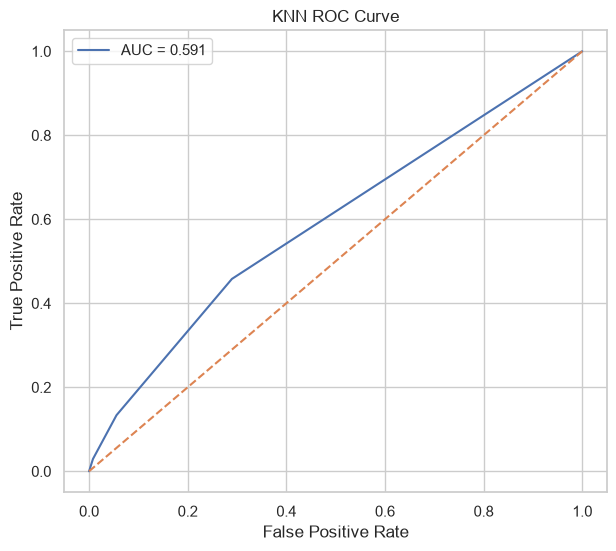

In [9]:
fpr, tpr, _ = roc_curve(y_test, y_prob)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot(
    [0,1],
    [0,1],
    "--"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("KNN ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Hyperparameter Analysis

The value of **K** influences the performance of the KNN classifier.

The following analysis evaluates model accuracy for different values of K to identify an appropriate neighborhood size.

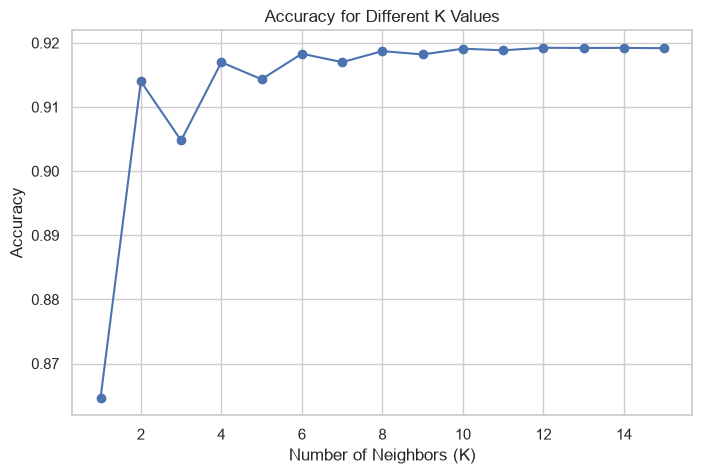

In [10]:
# ============================================================
# K Selection
# ============================================================

k_values = range(1, 16)

accuracy_scores = []

for k in k_values:

    model = KNeighborsClassifier(n_neighbors=k)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy_scores.append(
        accuracy_score(y_test, predictions)
    )

plt.figure(figsize=(8,5))

plt.plot(
    k_values,
    accuracy_scores,
    marker="o"
)

plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Accuracy")
plt.title("Accuracy for Different K Values")

plt.grid(True)

plt.show()

# Save Model Performance

The evaluation metrics of the KNN classifier are appended to the common model results file for later comparison with other classification algorithms.

In [11]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["K-Nearest Neighbors"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,K-Nearest Neighbors,0.914329,0.244966,0.029406,0.052509,0.591036,450,4819,146,56088


# Conclusion

The K-Nearest Neighbors classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- The KNN algorithm classified applicants based on similarity within the transformed feature space.
- Model performance was evaluated using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- The influence of the number of neighbors (K) on classification accuracy was investigated.
- Performance metrics were recorded for comparison with other machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 09 – Naïve Bayes Classifier**